In [1]:
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import subprocess
from pathlib import Path

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import squidpy as sq
from mudata import MuData
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from spatialleiden import spatialleiden_multimodal

from batch_integration.multisample_utils import preprocess_neighbors, preprocess_scaling
from utils import (
    DATA_DIR,
    RESULT_DIR,
    SHELL,
    activate_env_cmd,
    mm,
    rc_params,
    remove_tick_and_label,
)

mpl.rcParams.update(rc_params)

/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialleiden/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [3]:
seed = 42

spatialglue_dir = DATA_DIR / "SpatialGlue" / "Data_SpatialGlue"
spatialglue_results = RESULT_DIR / "SpatialGlue"

spatialglue_results.mkdir(exist_ok=True, parents=True)

# Prepare & Cluster

In [4]:
for simulation in spatialglue_dir.glob("*Simulation*"):
    dataset = simulation.name.split("_")[1]
    modalities = {}

    # load modalities
    for file in simulation.glob("*.h5ad"):
        modality = file.stem.split("_")[1]
        adata = ad.read_h5ad(file)
        adata.X = adata.layers["counts"]
        del adata.layers, adata.uns, adata.varm
        modalities[modality] = adata

    # prepare MuData
    mdata = MuData(modalities)
    mdata.var_names_make_unique()

    mdata.obs["groundtruth"] = pd.Categorical(
        mdata.mod["RNA"].obsm["spfac"].astype(int) @ np.array([1, 2, 3, 4])
    )

    mdata.obsm["spatial"] = mdata["RNA"].obsm["spatial"]

    for _, mod in mdata.mod.items():
        del mod.obsm["spatial"], mod.obsm["spfac"]

    # process modalities
    for name, adata in mdata.mod.items():
        n_pcs = 30 if name == "RNA" else 10
        preprocess_scaling(adata, n_pcs=n_pcs, center=True, seed=seed)
        preprocess_neighbors(adata, "X_pca", seed=seed)

    # spatial neighbors
    sq.gr.spatial_neighbors(mdata, coord_type="grid", n_neighs=8)

    # cluster
    spatialleiden_multimodal(
        mdata,
        resolution=0.5,
        layer_weights={"ADT": 1, "RNA": 1.5, "spatial": 2.5},
        random_state=seed,
    )

    # write output
    mdata.write_h5mu(spatialglue_results / f"{dataset}.h5mu")

    labels = mdata.obs[["groundtruth", "spatialleiden"]]
    labels[["x", "y"]] = mdata.obsm["spatial"]
    labels.to_parquet(spatialglue_results / f"{dataset}.parquet")

/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialleiden/lib/python3.12/site-packages/mudata/_core/mudata.py:571: UserWarning: Cannot join columns with the same name because var_names are intersecting.
  self._update_attr_legacy(attr, axis, join_common, **kwargs)
/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialleiden/lib/python3.12/site-packages/mudata/_core/mudata.py:1432: UserWarning: Modality names will be prepended to var_names since there are identical var_names in different modalities.
  warnings.warn(
/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialleiden/lib/python3.12/site-packages/mudata/_core/mudata.py:571: UserWarning: Cannot join columns with the same name because var_names are intersecting.
  self._update_attr_legacy(attr, axis, join_common, **kwargs)
/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/

# Run SpatialGlue

In [4]:
conda_cmd = activate_env_cmd("spatialglue")

script_dir = Path("other_methods")
script_path = script_dir / "spatialglue.py"

In [5]:
for h5mu in spatialglue_results.glob("*.h5mu"):
    name = h5mu.stem
    out_dir = spatialglue_results / "SpatialGlue"
    out_dir.mkdir(exist_ok=True, parents=True)
    out_file = out_dir / f"{name}.parquet"

    cmd = f"{script_path} {h5mu} {out_file}"

    subprocess.run(f"{conda_cmd} && {cmd}", shell=True, executable=SHELL)

/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialglue/lib/python3.8/site-packages/SpatialGlue/preprocess.py:132: UserWarning: torch.sparse.SparseTensor(indices, values, shape, *, device=) is deprecated.  Please use torch.sparse_coo_tensor(indices, values, shape, dtype=, device=). (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:641.)
  return torch.sparse.FloatTensor(indices, values, shape)
  0%|          | 0/600 [00:00<?, ?it/s]/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialglue/lib/python3.8/site-packages/SpatialGlue/model.py:212: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  self.alpha = F.softmax(torch.squeeze(self.vu) + 1e-6)
100%|██████████| 600/600 [00:16<00:00, 37.48it/s]
R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ 

Model training finished!

fitting ...
  |======================================================================| 100%


/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialglue/lib/python3.8/site-packages/SpatialGlue/preprocess.py:132: UserWarning: torch.sparse.SparseTensor(indices, values, shape, *, device=) is deprecated.  Please use torch.sparse_coo_tensor(indices, values, shape, dtype=, device=). (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:641.)
  return torch.sparse.FloatTensor(indices, values, shape)
  0%|          | 0/600 [00:00<?, ?it/s]/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialglue/lib/python3.8/site-packages/SpatialGlue/model.py:212: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  self.alpha = F.softmax(torch.squeeze(self.vu) + 1e-6)
100%|██████████| 600/600 [00:12<00:00, 48.10it/s]
R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ 

Model training finished!

fitting ...
  |======================================================================| 100%


/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialglue/lib/python3.8/site-packages/SpatialGlue/preprocess.py:132: UserWarning: torch.sparse.SparseTensor(indices, values, shape, *, device=) is deprecated.  Please use torch.sparse_coo_tensor(indices, values, shape, dtype=, device=). (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:641.)
  return torch.sparse.FloatTensor(indices, values, shape)
  0%|          | 0/600 [00:00<?, ?it/s]/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialglue/lib/python3.8/site-packages/SpatialGlue/model.py:212: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  self.alpha = F.softmax(torch.squeeze(self.vu) + 1e-6)
100%|██████████| 600/600 [00:12<00:00, 48.80it/s]
R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ 

Model training finished!

fitting ...
  |======================================================================| 100%


/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialglue/lib/python3.8/site-packages/SpatialGlue/preprocess.py:132: UserWarning: torch.sparse.SparseTensor(indices, values, shape, *, device=) is deprecated.  Please use torch.sparse_coo_tensor(indices, values, shape, dtype=, device=). (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:641.)
  return torch.sparse.FloatTensor(indices, values, shape)
  0%|          | 0/600 [00:00<?, ?it/s]/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialglue/lib/python3.8/site-packages/SpatialGlue/model.py:212: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  self.alpha = F.softmax(torch.squeeze(self.vu) + 1e-6)
100%|██████████| 600/600 [00:12<00:00, 48.66it/s]
R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ 

Model training finished!

fitting ...
  |======================================================================| 100%


/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialglue/lib/python3.8/site-packages/SpatialGlue/preprocess.py:132: UserWarning: torch.sparse.SparseTensor(indices, values, shape, *, device=) is deprecated.  Please use torch.sparse_coo_tensor(indices, values, shape, dtype=, device=). (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:641.)
  return torch.sparse.FloatTensor(indices, values, shape)
  0%|          | 0/600 [00:00<?, ?it/s]/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialglue/lib/python3.8/site-packages/SpatialGlue/model.py:212: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  self.alpha = F.softmax(torch.squeeze(self.vu) + 1e-6)
100%|██████████| 600/600 [00:12<00:00, 48.77it/s]
R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ 

Model training finished!

fitting ...
  |======================================================================| 100%


# Plotting & metrics

In [6]:
from scipy.optimize import linear_sum_assignment

In [7]:
scatter_kwargs = dict(
    s=3,
    lw=0,
    palette=dict(zip([1, 2, 3, 4, 0], sns.color_palette("tab10"))),
    legend=False,
)

methods = ["groundtruth", "spatialleiden", "SpatialGlue"]

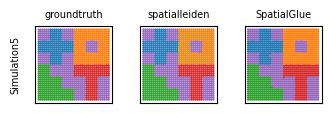

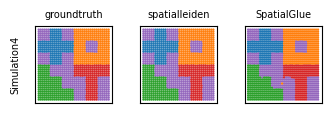

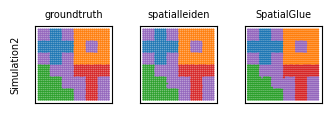

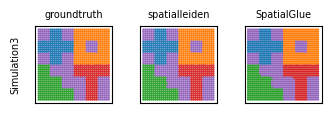

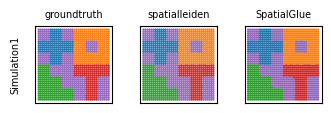

In [8]:
scores = []

for file in spatialglue_results.glob("*.parquet"):
    labels = (
        pd.read_parquet(file)
        .astype({"spatialleiden": "category", "groundtruth": "category"})
        .join(pd.read_parquet(file.parent / "SpatialGlue" / file.name))
        .astype({"SpatialGlue": "category"})
    )

    # match clusters
    for name in ["spatialleiden", "SpatialGlue"]:
        contingency_table = pd.crosstab(labels[name], labels["groundtruth"])
        row_ind, col_ind = linear_sum_assignment(contingency_table, maximize=True)
        labels[name] = labels[name].cat.rename_categories(
            dict(
                zip(
                    contingency_table.index[row_ind], contingency_table.columns[col_ind]
                )
            )
        )

    fig, axs = plt.subplots(
        ncols=len(methods), sharex=True, sharey=True, figsize=(90 * mm, 30 * mm)
    )
    for label, ax in zip(methods, axs):
        _ = sns.scatterplot(
            data=labels, x="x", y="y", hue=label, ax=ax, **scatter_kwargs
        )
        ax.set(title=label, aspect=1)
        remove_tick_and_label(ax)
    axs[0].set(ylabel=file.stem)
    fig.tight_layout()

    for tool in ["spatialleiden", "SpatialGlue"]:
        ari = adjusted_rand_score(
            labels["groundtruth"].cat.codes, labels[tool].cat.codes
        )
        nmi = normalized_mutual_info_score(
            labels["groundtruth"].cat.codes, labels[tool].cat.codes
        )

        scores.append({"sample": file.stem, "ARI": ari, "NMI": nmi, "tool": tool})

scores = (
    pd.DataFrame(scores)
    .set_index("sample")
    .rename(columns={"spatialleiden": "SpatialLeiden"})
)

In [9]:
file = Path("results/SpatialGlue/Simulation1.parquet")
labels = (
    pd.read_parquet(file)
    .astype({"spatialleiden": "category", "groundtruth": "category"})
    .join(pd.read_parquet(file.parent / "SpatialGlue" / file.name))
    .astype({"SpatialGlue": "category"})
)

# match clusters
for name in ["spatialleiden", "SpatialGlue"]:
    contingency_table = pd.crosstab(labels[name], labels["groundtruth"])
    row_ind, col_ind = linear_sum_assignment(contingency_table, maximize=True)
    labels[name] = labels[name].cat.rename_categories(
        dict(zip(contingency_table.index[row_ind], contingency_table.columns[col_ind]))
    )

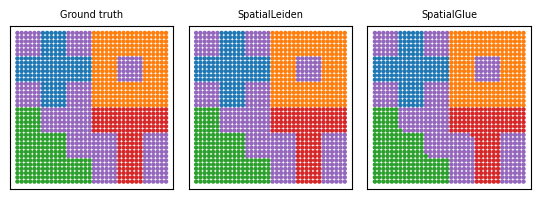

In [10]:
scatter_kwargs["s"] = 10

fig, axs = plt.subplots(ncols=3, figsize=(140 * mm, 50 * mm))

for label, ax in zip(methods, axs[:3]):
    _ = sns.scatterplot(data=labels, x="x", y="y", hue=label, ax=ax, **scatter_kwargs)
    ax.set(title=label, aspect=1)
    remove_tick_and_label(ax)
axs[0].set(title="Ground truth")
axs[1].set(title="SpatialLeiden")


fig.tight_layout()
fig.savefig(spatialglue_results / "domains.pdf")

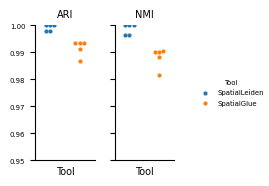

In [19]:
scores_df = scores.melt(
    id_vars=["tool"], var_name="metric", value_name="value", ignore_index=False
).assign(tool=lambda df: df["tool"].replace({"spatialleiden": "SpatialLeiden"}))

g = sns.FacetGrid(data=scores_df, hue="tool", col="metric", height=50 * mm, aspect=0.5)
g.map_dataframe(sns.swarmplot, x="tool", y="value", s=3)
g.set_titles(col_template="{col_name}")
g.set(ylim=(0.95, 1), ylabel=None, xlabel="Tool")
g.add_legend(title="Tool")

for ax in g.axes.flat:
    ax.tick_params(axis="x", labelrotation=45, pad=0)
    ax.set_xticks([])

_ = g.tight_layout()

g.savefig(spatialglue_results / "metrics.pdf")